# Group 3 | Seasonal Climatology

**Predicting Drought Before the Rains Fail**

District-level severe meteorological drought, Tanzania (1981–2025).

## 6. Baseline performance evaluation

**Objective.** Quantify how well historical seasonal risk probabilities distinguish severe-drought months from non-severe months.

**Validation period:** 2015–2018. A warning threshold is selected by maximizing F2 on one-month validation targets only. **Retrospective case study:** 2020–2022. These years were previously analysed and are not a pristine, independent holdout set.

Forecast verification uses Brier Score, ROC-AUC, average precision, recall, precision and false warnings. Scores describe SPI-3 severe-drought months—not crop or livestock damage.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "outputs"
for name in ["figures", "maps", "metrics", "predictions", "tables"]:
    (OUT / name).mkdir(parents=True, exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from group3_climatology.data import load_data
from group3_climatology.baseline import forecast_table
from group3_climatology.evaluation import validation_threshold, evaluation_by_period, onset_warnings, score_forecasts, monthly_case_study
from group3_climatology.plots import plot_case_study, plot_confusion, plot_probability_bins
from group3_climatology.config import INPUT

data=load_data(INPUT)
forecasts=forecast_table(data)
threshold,ranked=validation_threshold(forecasts)
print(f"Validation-selected warning threshold: {threshold:.1%}")
display(ranked.head(10))
ranked.to_csv(OUT / "metrics" / "validation_threshold_search.csv",index=False)

Validation-selected warning threshold: 5.5%


,threshold,f2_score,precision,recall,true_alerts,false_alerts
0,0.055,0.300064,0.085077,0.814815,374,4022
1,0.030,0.292573,0.080762,0.849673,390,4439
2,0.050,0.283505,0.078571,0.814815,374,4386
3,0.045,0.283505,0.078571,0.814815,374,4386
4,0.040,0.283505,0.078571,0.814815,374,4386
5,0.035,0.283505,0.078571,0.814815,374,4386
6,0.025,0.283254,0.073487,0.989107,454,5724
7,0.020,0.283254,0.073487,0.989107,454,5724
8,0.015,0.283254,0.073487,0.989107,454,5724
9,0.010,0.283254,0.073487,0.989107,454,5724


### Evaluation measures

The Brier Score is the average squared probability error:

$$BS=\frac{1}{n}\sum_{i=1}^{n}(\hat p_i-y_i)^2.$$

A smaller Brier Score is better. ROC-AUC measures discrimination; average precision summarizes precision-recall performance. False-warning totals depend on the chosen alert threshold and the number of forecast opportunities.

In [2]:
evaluation=evaluation_by_period(forecasts,threshold)
evaluation.to_csv(OUT / "metrics" / "model_evaluation.csv",index=False)
view=evaluation[evaluation.period.isin(["validation_2015_2018","case_study_2020_2022","retrospective_2023_2025"])]
display(view[["period","lead_months","forecasts","severe_district_months","roc_auc","brier_score","precision","recall","false_alerts","missed_drought_months"]].round(4))

,period,lead_months,forecasts,severe_district_months,roc_auc,brier_score,precision,recall,false_alerts,missed_drought_months
0,validation_2015_2018,1,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
1,validation_2015_2018,2,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
2,validation_2015_2018,3,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
6,case_study_2020_2022,1,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
7,case_study_2020_2022,2,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
8,case_study_2020_2022,3,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
9,retrospective_2023_2025,1,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48
10,retrospective_2023_2025,2,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48
11,retrospective_2023_2025,3,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48


### Main case study: 2020–2022

Each forecast at a given horizon is one district-month prediction. For comparability, the confusion matrix below uses only the one-month lead. Baseline forecasts have identical risk probabilities at all three leads for each target.

,2020–2022 result
forecasts,5400.000000
severe_district_months,150.000000
severe_event_rate,0.027778
mean_predicted_probability,0.057563
brier_score,0.028744
roc_auc,0.550170
average_precision,0.031318
warning_threshold,0.055000
true_alerts,84.000000
false_alerts,2307.000000


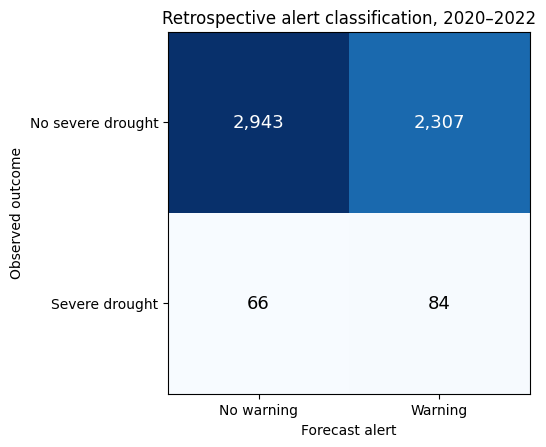

In [3]:
case=forecasts[(forecasts.target_month.dt.year.between(2020,2022)) & (forecasts.horizon_months==1)]
result=score_forecasts(case,threshold)
display(pd.DataFrame([result]).T.rename(columns={0:"2020–2022 result"}))
assert result["true_alerts"]==84 and result["false_alerts"]==2307
assert result["missed_drought_months"]==66 and result["correct_nonalerts"]==2943
fig=plot_confusion(result,OUT / "figures" / "2020_2022_warning_confusion.png")
plt.show();plt.close(fig)

### Observed drought versus historical risk

The baseline forecasts the historical seasonal event rate. It does not incorporate unusual rainfall conditions developing within 2020–2022.

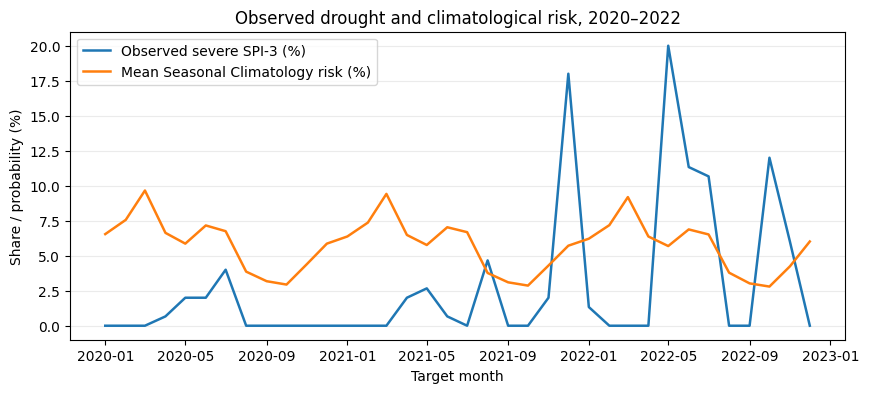

In [4]:
timeline=monthly_case_study(forecasts)
timeline.to_csv(OUT / "tables" / "2020_2022_observed_vs_forecast.csv",index=False)
fig=plot_case_study(timeline,OUT / "figures" / "2020_2022_observed_vs_baseline.png")
plt.show();plt.close(fig)

### Reliability and onset verification

Reliability compares forecast probabilities with observed frequencies. Onset is counted only when a severe SPI-3 month follows a preceding non-severe month. Onset verification is reported separately from all severe-drought months.

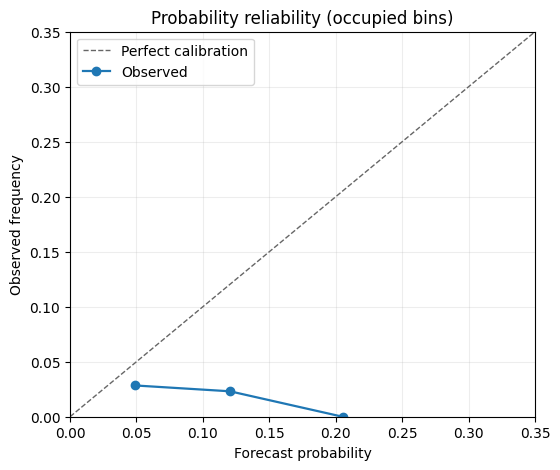

,band,mean_prediction,actual_rate,sample_size
0,"(-0.001, 0.1]",0.0489,0.0284,4748
1,"(0.1, 0.2]",0.1204,0.0231,649
2,"(0.2, 0.3]",0.2051,0.0000,3


,observed_new_severe_onsets,onset_months_with_warning,onset_months_without_warning
0,109,55,54


In [5]:
fig,reliability=plot_probability_bins(case,OUT / "figures" / "2020_2022_reliability.png")
plt.show();plt.close(fig)
display(reliability.round(4))
onsets=onset_warnings(forecasts,threshold)
display(pd.DataFrame([onsets]))

### Interpretation

The warning threshold was chosen to favor recall, generating substantial false alerts. Equal probability forecasts across leads should not be interpreted as evidence of three months of useful event-specific warning. None of these scores establish the time between warnings and agricultural impacts.